# Numerical Differentation

Here we will study how to compute derivatives:

- Analitically using ``sympy``.

- Numerically using different approaches for finite-difference methods.

In [1]:
# Import libraries

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

## Example: Analytical functions:

Find the derivative of:

$y(t) = 2 + 3\,t^2$


## 1. Analytical derivatives: Find derivatives using symbolic algebra

- ``sp.diff``: calculate derivatives

- ``sp.lambdify``: sympy to numpy objects

In [2]:
# Define the function
def y(t):
    """
    Evaluates the function for y(t).
    """
    return 2. + 3.*t**2

In [3]:
# Define symbols

t = sp.symbols('t')

In [5]:
# Define the function derivative
def deriv_t(t):
    """
    Calculates first derivative derivative .diff()
    """
    return sp.diff(y(t), t)

In [6]:
# Check objects

print(y(t))

print(type(y))

3.0*t**2 + 2.0
<class 'function'>


In [7]:
print(deriv_t(t))

print(type(deriv_t))

6.0*t
<class 'function'>


In [8]:
# Lambify our functions

deriv_t2 = sp.lambdify(t, deriv_t(t), "numpy")

In [9]:
print(type(deriv_t2))

<class 'function'>


### Result:

In [10]:
print("Result of the derivaitve: ", deriv_t2(t))

Result of the derivaitve:  6.0*t


### Plots:

In [11]:
# First we define the time axis

t_axis = np.arange(0., 10., 0.1)

In [12]:
# Evaluate original function
y_axis = y(t_axis)

#print(y_axis)

# Evaluate the derivative
y_deriv = deriv_t2(t_axis)

#print(y_deriv)

### Original function:

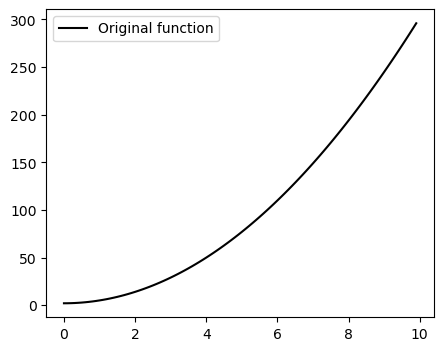

In [13]:
fig, ax = plt.subplots(figsize=(5,4))

ax.plot(t_axis, y(t_axis), color ="black", linestyle="-", label='Original function') # Original data

ax.legend()

plt.show()

### Derivative:

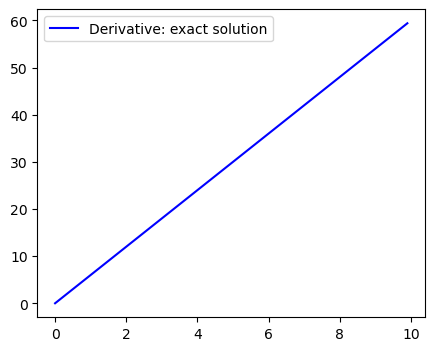

In [14]:
fig, ax = plt.subplots(figsize=(5,4))

ax.plot(t_axis, deriv_t2(t_axis), color ="blue", linestyle="-", label='Derivative: exact solution') # Original data

ax.legend()

plt.show()

## 2. Numerical derivatives: Find derivatives using finite differences.

Imagine we want to calculate the derivative as a function of time, using some data, $f$.

We can use the definition of derivative using the limit:

$$\dot{f}=\frac{df}{dt}=\lim_{\Delta t \to 0} \frac{f(t + \Delta t) - f(t)}{\Delta t}$$

If we remove the limit, we have a **finite-difference formula**:

$$\dot{f}=\frac{df}{dt}= \frac{f(t + \Delta t) - f(t)}{\Delta t} + {\cal O}(\Delta t)$$

whiere ${\cal O}(\Delta t)$ is the truncation error term (from a Taylor expansion).

The above equation can also be written with indices:

$$\dot{f}=\frac{df}{dt}= \frac{f_{i+1} - f_i}{\Delta t} + {\cal O}(\Delta t)$$

### Forward finite differences:

Notice the above derivative includes a term on the right, so we are using a **(forward) finite difference scheme**, i.e.,

$$\dot{f}\approx\frac{\Delta f}{\Delta t}\Rightarrow \dot{f}=\frac{f_{i+1}-f_i}{t_{i+1}-t_i}+O(\Delta t)$$


### Backward finite differences:

Alternatively, we can use **(backward) finite difference scheme**, i.e.,

$$\dot{f}\approx\frac{\Delta f}{\Delta t}\Rightarrow \dot{f}=\frac{f_{i}-f_{i-1}}{t_{i}-t_{i-1}}+O(\Delta t)$$

where $O(\Delta t)$ is the error and we take the point to the left, and note that $O(\Delta t)\to 0$ when $\Delta t\to 0$ (the method is consistent).

### Central finite differences:

Both (forward and backward) finite difference methods are only first order, so it is generally more convenient to use a **(second order) central difference method**, i.e.,

$$\dot{f}\approx\frac{\Delta f}{\Delta t}\Rightarrow \dot{f}=\frac{f_{i+1}-f_{i-1}}{t_{i+1}-t_{i-1}}+O(\Delta t^2)$$

where we take the point to the left and also the point to the right, which results in second-order accuracy. This also comes from its Taylor expansion.

An alternative formula considers the **mid-points** to the left and right:

$$\dot{f}\approx\frac{\Delta f}{\Delta t}\Rightarrow \dot{f}=\frac{f_{i+1/2}-f_{i-1/2}}{t_{i+1/2}-t_{i-1/2}}+O(\Delta t^2)$$

The latter is more convenient as we show later.

### Forward difference method:

We use this definition for forward differences:

$$\dot{f}\approx \frac{f(t+h) - f(t)}{h}$$

Notice we are calling $h\equiv \Delta t$.

In [16]:
# Fix step size
h = 0.5 # delta t

# Define FD algorithm.
forward_diff = (y(t_axis + h) - y(t_axis))/(h)

In [17]:
#print(forward_diff)

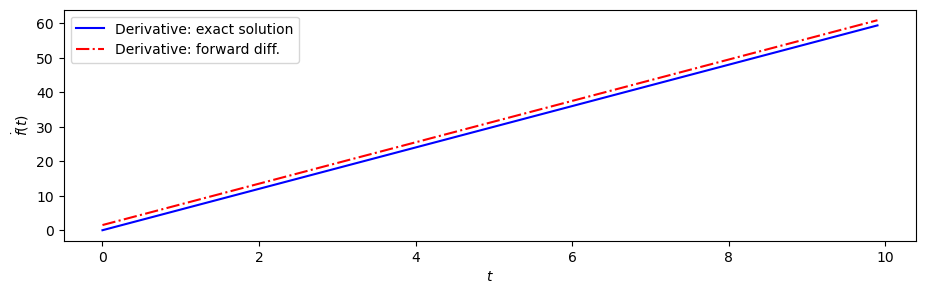

In [18]:
# Plot solution

fig, ax = plt.subplots(figsize=(11,3))

ax.plot(t_axis, deriv_t2(t_axis), color ="blue", linestyle="-", label='Derivative: exact solution') # Original data
ax.plot(t_axis, forward_diff, color ="red", linestyle="-.", label='Derivative: forward diff.') # Original data

ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$\dot{f}(t)$")
ax.legend()
plt.show()

In [19]:
# Fix step size
h_2 = 0.1

# Define FD algorithm.
forward_diff2 = (y(t_axis + h_2) - y(t_axis))/(h_2)

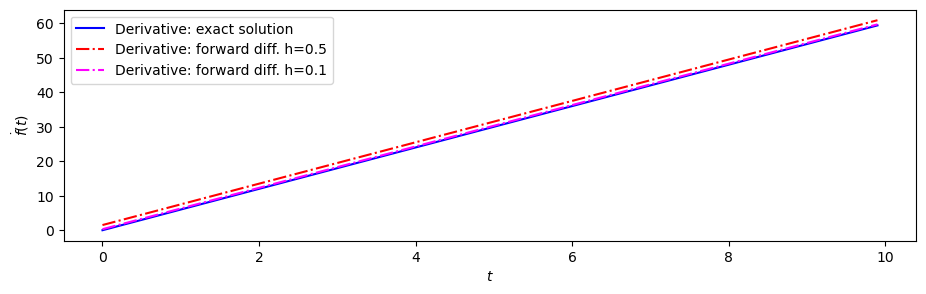

In [20]:
# Plot solution

fig, ax = plt.subplots(figsize=(11,3))

ax.plot(t_axis, deriv_t2(t_axis), color ="blue", linestyle="-", label='Derivative: exact solution') # Original data
ax.plot(t_axis, forward_diff, color ="red", linestyle="-.", label='Derivative: forward diff. h=0.5') # Original data
ax.plot(t_axis, forward_diff2, color ="magenta", linestyle="-.", label='Derivative: forward diff. h=0.1') # Original data
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$\dot{f}(t)$")
ax.legend()
plt.show()

### Error calculation:


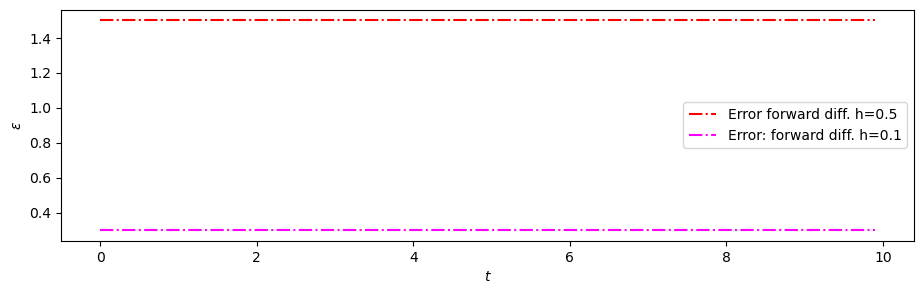

In [21]:
# Plot solution

fig, ax = plt.subplots(figsize=(11,3))

#ax.plot(t_axis, deriv_t2(t_axis), color ="blue", linestyle="-", label='Derivative: exact solution') # Original data
ax.plot(t_axis, abs(forward_diff - deriv_t2(t_axis)), color ="red", linestyle="-.", label='Error forward diff. h=0.5') # Original data
ax.plot(t_axis, abs(forward_diff2 - deriv_t2(t_axis)), color ="magenta", linestyle="-.", label='Error: forward diff. h=0.1') # Original data

plt.xlabel(r"$t$")
plt.ylabel(r"$\epsilon$")

ax.legend()
plt.show()

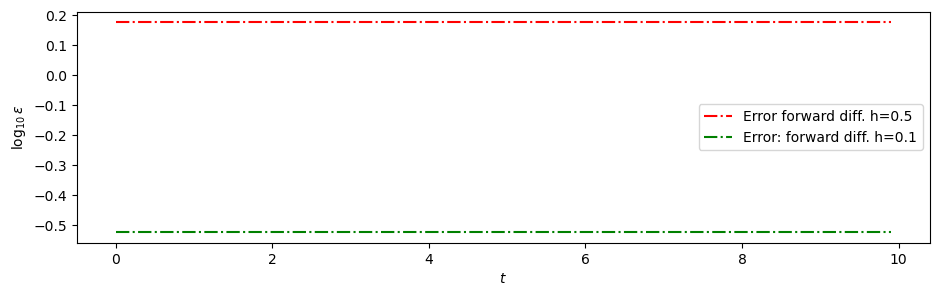

In [22]:
# Plot solution

fig, ax = plt.subplots(figsize=(11,3))

#ax.plot(t_axis, deriv_t2(t_axis), color ="blue", linestyle="-", label='Derivative: exact solution') # Original data
ax.plot(t_axis, np.log10(abs(forward_diff - deriv_t2(t_axis))), color ="red", linestyle="-.", label='Error forward diff. h=0.5') # Original data
ax.plot(t_axis, np.log10(abs(forward_diff2 - deriv_t2(t_axis))), color ="green", linestyle="-.", label='Error: forward diff. h=0.1') # Original data

plt.xlabel(r"$t$")
plt.ylabel(r"$\log_{10}\epsilon$")

ax.legend()
plt.show()

### Backward difference method:

We use this definition for backward differences:

$$\dot{f}\approx \frac{f(t-h) - f(t)}{-h}$$

In [23]:
# Define our BD method

backward_diff = (y(t_axis - h) - y(t_axis))/(-h)


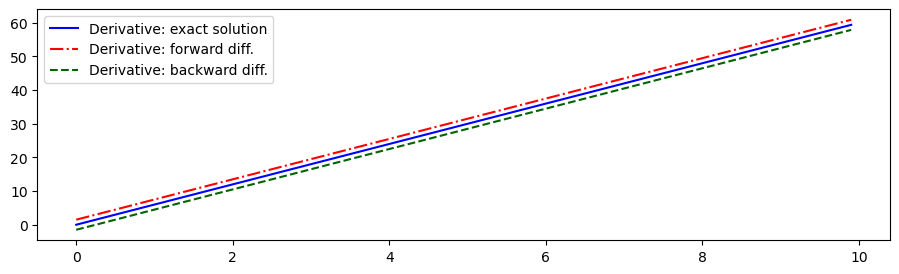

In [24]:
fig, ax = plt.subplots(figsize=(11,3))

ax.plot(t_axis, deriv_t2(t_axis), color ="blue", linestyle="-", label='Derivative: exact solution') # Original data
ax.plot(t_axis, forward_diff, color ="red", linestyle="-.", label='Derivative: forward diff.') # Original data
ax.plot(t_axis, backward_diff, color ="darkgreen", linestyle="--", label='Derivative: backward diff.') # Original data

ax.legend()
plt.show()

In [25]:
# Define our BD method

backward_diff2 = (y(t_axis - h_2) - y(t_axis))/(-h_2)

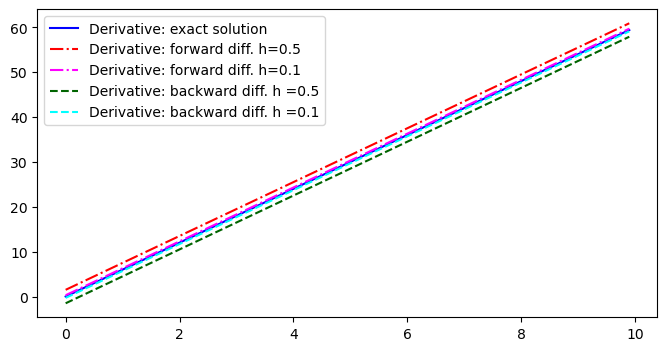

In [26]:
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(t_axis, deriv_t2(t_axis), color ="blue", linestyle="-", label='Derivative: exact solution') # Original data
ax.plot(t_axis, forward_diff, color ="red", linestyle="-.", label='Derivative: forward diff. h=0.5') # Original data
ax.plot(t_axis, forward_diff2, color ="magenta", linestyle="-.", label='Derivative: forward diff. h=0.1') # Original data
ax.plot(t_axis, backward_diff, color ="darkgreen", linestyle="--", label='Derivative: backward diff. h =0.5') # Original data
ax.plot(t_axis, backward_diff2, color ="cyan", linestyle="--", label='Derivative: backward diff. h =0.1') # Original data

ax.legend()
plt.show()

### Central difference method:

We use this definition for central differences with half points:

$$\dot{f} \approx \frac{f(t+h/2) - f(t-h/2)}{h}$$


In [27]:
# Code the CD method:

central_diff = (y(t_axis + h/2) - y(t_axis - h/2))/(h)

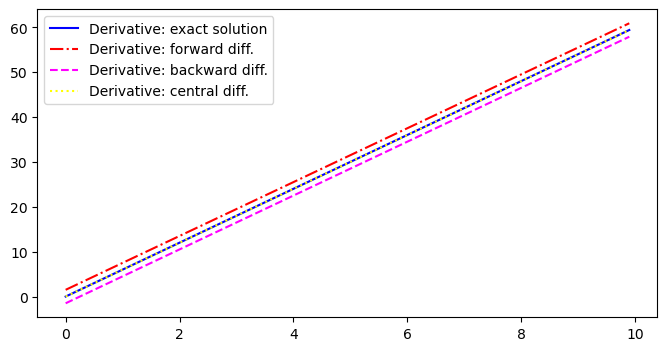

In [28]:
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(t_axis, deriv_t2(t_axis), color ="blue", linestyle="-", label='Derivative: exact solution') # Original data
ax.plot(t_axis, forward_diff, color ="red", linestyle="-.", label='Derivative: forward diff.') # Original data
ax.plot(t_axis, backward_diff, color ="magenta", linestyle="--", label='Derivative: backward diff.') # Original data
ax.plot(t_axis, central_diff, color ="yellow", linestyle=":", label='Derivative: central diff.') # Original data

ax.legend()
plt.show()

## 3. Numerical derivatives: Find derivatives using shifted arrays

When we are hard coding derivative in any programming language, we can use the shifted array method.

In the case analysed here, that means shifting both the $f$ and the $t$ arrays by removing elements on the left and right.

In [31]:
# Example

print(t_axis.shape)
print(t_axis[:3])
print(t_axis[-3:])

(100,)
[0.  0.1 0.2]
[9.7 9.8 9.9]


In [28]:
print(y_axis.shape)

(100,)


### Shifted arrays:

In [29]:
t_left  = t_axis[1:]
t_right = t_axis[:-1]

y_left  = y_axis[1:]
y_right = y_axis[:-1]

In [30]:
# Safe check
print(t_left[:3])
print(t_right[-3:])

[0.1 0.2 0.3]
[9.6 9.7 9.8]


In [32]:
print(t_axis[:5])
print(t_left[:5])

print(t_axis[-5:])
print(t_right[-5:])

[0.  0.1 0.2 0.3 0.4]
[0.1 0.2 0.3 0.4 0.5]
[9.5 9.6 9.7 9.8 9.9]
[9.4 9.5 9.6 9.7 9.8]


In [33]:
print(t_axis[1] - t_axis[0])
print(t_right[0] - t_left[0])

0.1
-0.1


In [34]:
print(t_axis.shape)

(100,)


In [35]:
print(t_right.shape, t_left.shape)

(99,) (99,)


### Derivative:

In [36]:
deriv_y = (y_right - y_left)/(t_right - t_left)

In [37]:
print(deriv_y.shape)

(99,)


### Mid-points:

In [38]:
t_mid = 0.5*(t_right + t_left)

In [39]:
print(t_mid.shape)

(99,)


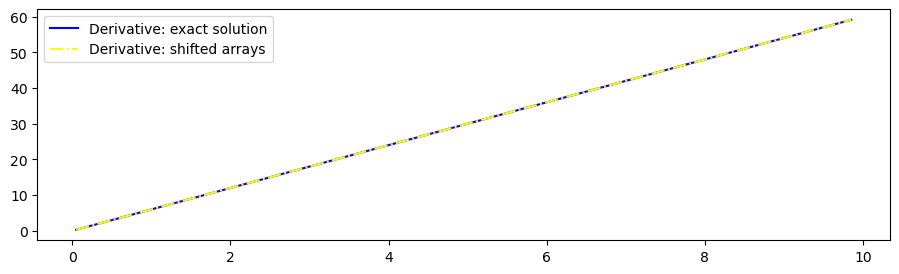

In [40]:
fig, ax = plt.subplots(figsize=(11,3))

ax.plot(t_mid, deriv_t2(t_mid), color ="blue", linestyle="-", label='Derivative: exact solution') # Original data
#ax.plot(t_axis, forward_diff, color ="red", linestyle="-.", label='Derivative: forward diff.') # Original data
#ax.plot(t_axis, backward_diff, color ="green", linestyle="--", label='Derivative: backward diff.') # Original data
#ax.plot(t_axis, central_diff, color ="yellow", linestyle=":", label='Derivative: central diff.') # Original data
ax.plot(t_mid, deriv_y, color ="yellow", linestyle="-.", label='Derivative: shifted arrays') # Original data

ax.legend()
plt.show()